In [ ]:
from pathlib import Path
from google.colab import drive
import os
import cv2
import matplotlib.pyplot as plt
import random
import numpy as np
import pandas as pd
import seaborn as sns


In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_dir = Path('/content/drive/MyDrive/CS231/Data/train')
test_dir = Path('/content/drive/MyDrive/CS231/Data/test')


train:
rose: 703
sunflower: 671
tulip: 790
daisy: 698
Total in train: 2862

test:
rose: 80
sunflower: 80
tulip: 100
daisy: 83
Total in test: 343


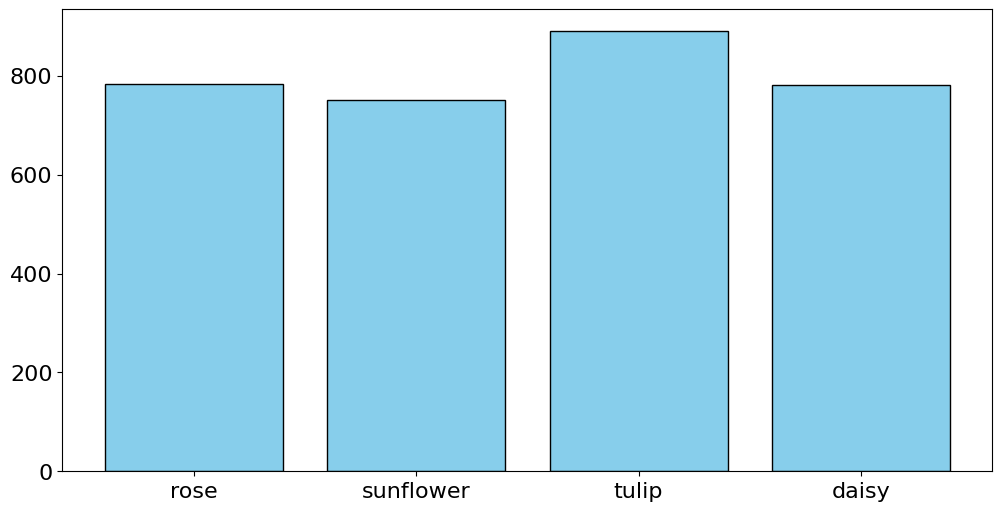


Thống kê ảnh:
rose: 783
sunflower: 751
tulip: 890
daisy: 781
Tổng: 3205


In [ ]:
# Thống kê ảnh
def count_images(data_dir):
    class_counts = {}
    for sub_data_dir in os.listdir(data_dir):  # Duyệt qua các thư mục train/test
        sub_data_path = os.path.join(data_dir, sub_data_dir)

        if os.path.isdir(sub_data_path):
            print(f"\n{sub_data_dir}:")
            total = 0

            for class_dir in os.listdir(sub_data_path): # Duyệt qua các thư mục hoa
                class_dir_path = os.path.join(sub_data_path, class_dir)

                if os.path.isdir(class_dir_path):
                    count = len(os.listdir(class_dir_path))
                    print(f"{class_dir}: {count}")
                    total += count
                    class_counts[class_dir] = class_counts.get(class_dir, 0) + count

            print(f"Total in {sub_data_dir}: {total}")

    plt.figure(figsize=(12, 6))
    plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.show()

    print("\nThống kê ảnh:")
    for class_name, count in class_counts.items():
       print(f"{class_name}: {count}")
    print(f"Tổng: {sum(class_counts.values())}")

data_dir = "/content/drive/MyDrive/CS231/Data"

count_images(data_dir)



In [ ]:
from skimage.feature import hog
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler

FEATURE ENGINEERING

In [ ]:
# Hàm trích xuất Color Histogram với HSV
def extract_histogram(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    hist_hue = cv2.calcHist([hsv], [0], None, [180], [0, 179])
    hist_saturation = cv2.calcHist([hsv], [1], None, [256], [0, 255])
    hist_value = cv2.calcHist([hsv], [2], None, [256], [0, 255])

    hist_hue /= hist_hue.sum()
    hist_saturation /= hist_saturation.sum()
    hist_value /= hist_value.sum()

    color_hist = np.concatenate([hist_hue.flatten(),
                                 hist_saturation.flatten(),
                                 hist_value.flatten()])

    return color_hist

# Hàm trích xuất HOG
def extract_hog(image):
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    fd, _ = hog(gray_image, orientations=9, pixels_per_cell=(8, 8),
                cells_per_block=(2, 2), visualize=True)
    return fd



In [ ]:
rose_dir = '/content/drive/MyDrive/CS231/Data/train/rose'

image_files = [f for f in os.listdir(rose_dir) if f.endswith(('.jpg', '.jpeg', '.png'))]

#image_file = image_files[0]
image_file = random.choice(image_files)

image_path = os.path.join(rose_dir, image_file)
image = cv2.imread(image_path)

In [ ]:
def display_original_image(image):
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

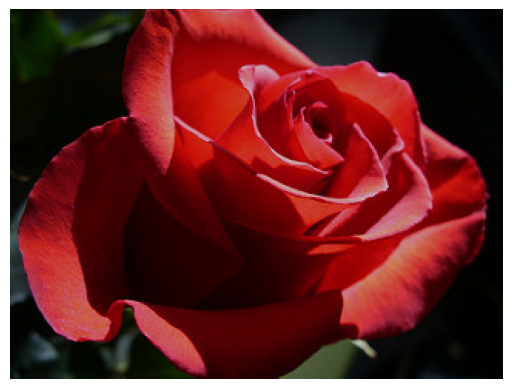

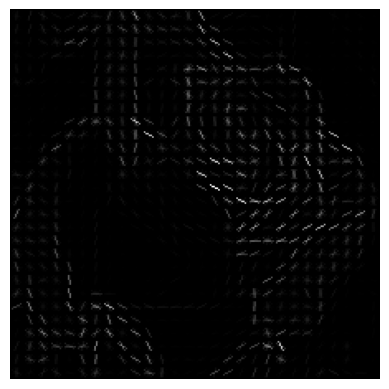

In [ ]:
# HOG
display_original_image(image)

image_resized = cv2.resize(image, (224,224))
image_gray = cv2.cvtColor(image_resized, cv2.COLOR_BGR2GRAY)

features, hog_image = hog(
    image_gray,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True
)

plt.imshow(hog_image, cmap='gray')
plt.axis('off')

plt.show()


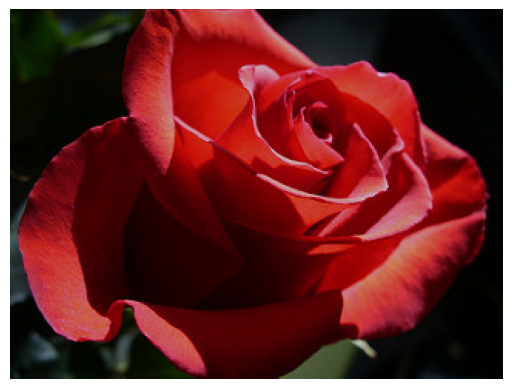

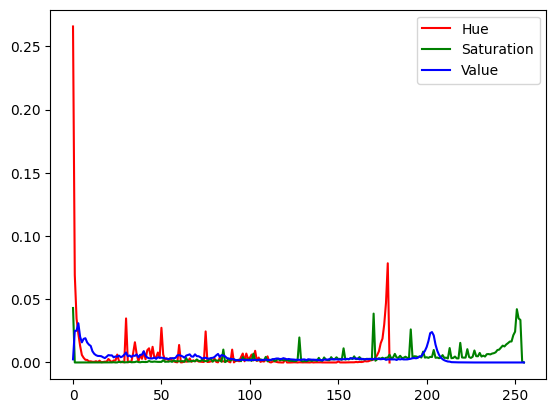

In [ ]:
# Color Histogram
display_original_image(image)

image_resized = cv2.resize(image, (224,224))
image_hsv = cv2.cvtColor(image_resized, cv2.COLOR_BGR2HSV)

hist_hue = cv2.calcHist([image_hsv], [0], None, [180], [0, 179])
hist_saturation = cv2.calcHist([image_hsv], [1], None, [256], [0, 255])
hist_value = cv2.calcHist([image_hsv], [2], None, [256], [0, 255])

hist_hue /= hist_hue.sum()
hist_saturation /= hist_saturation.sum()
hist_value /= hist_value.sum()

plt.figure()
plt.plot(hist_hue, label='Hue', color='r')
plt.plot(hist_saturation, label='Saturation', color='g')
plt.plot(hist_value, label='Value', color='b')

plt.legend()
plt.show()


LOAD DATA VÀ TRÍCH XUẤT ĐẶC TRƯNG COLOR HISTOGRAM

In [ ]:
def load_data(data_dir):
    features, labels = [], []
    for label in os.listdir(data_dir):
        label_path = os.path.join(data_dir, label)
        for img in os.listdir(label_path):
          img_path = os.path.join(label_path, img)
          if img.endswith(('.jpg', '.png', '.jpeg')):
            image = cv2.imread(img_path)
            image = cv2.resize(image, (224,224))

            color_hist = extract_histogram(image)

            features.append(color_hist)
            labels.append(label)

    return np.array(features), np.array(labels)


In [ ]:
X_train, y_train = load_data(train_dir)
X_test, y_test = load_data(test_dir)

In [ ]:
print(X_train.shape)
print(y_test.shape)
print(X_train.shape)
print(y_test.shape)

(2862, 692)
(343,)
(2862, 692)
(343,)


In [ ]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

In [ ]:
for i, label in enumerate(label_encoder.classes_):
    print(f"{i}: {label}")


0: daisy
1: rose
2: sunflower
3: tulip


RANDOM FOREST DÙNG COLOR HISTOGRAM

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=10, random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy: ", accuracy_score(y_test, y_pred_rf))

print('\n',classification_report(y_test, y_pred_rf))


Random Forest Accuracy:  0.6676384839650146

               precision    recall  f1-score   support

           0       0.67      0.75      0.70        83
           1       0.58      0.61      0.60        80
           2       0.79      0.75      0.77        80
           3       0.64      0.58      0.61       100

    accuracy                           0.67       343
   macro avg       0.67      0.67      0.67       343
weighted avg       0.67      0.67      0.67       343



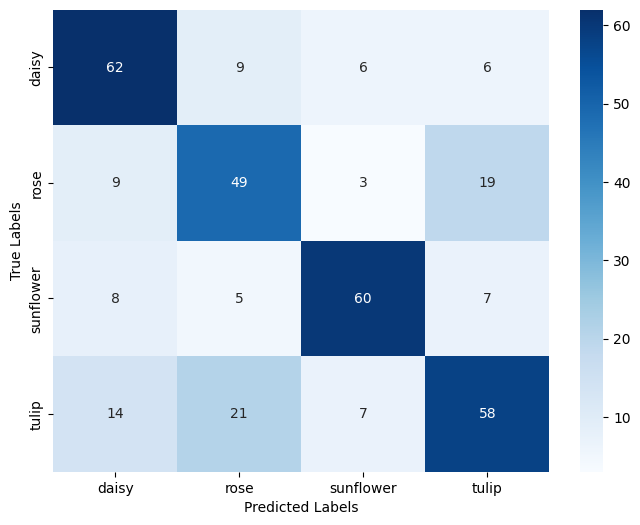

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

label_mapping = {0: 'daisy', 1: 'rose', 2: 'sunflower', 3: 'tulip'}
classes = [label_mapping[i] for i in range(len(label_mapping))]

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

LOAD DATA VÀ TRÍCH XUẤT ĐẶC TRƯNG HOG

In [ ]:
def load_data(data_dir):
    features, labels = [], []
    for label in os.listdir(data_dir):
        label_path = os.path.join(data_dir, label)
        for img in os.listdir(label_path):
          img_path = os.path.join(label_path, img)
          if img.endswith(('.jpg', '.png', '.jpeg')):
            image = cv2.imread(img_path)
            image = cv2.resize(image, (224,224))

            hog = extract_hog(image)

            features.append(hog)
            labels.append(label)

    return np.array(features), np.array(labels)

In [ ]:
X_train, y_train = load_data(train_dir)
X_test, y_test = load_data(test_dir)

In [ ]:
print(X_train.shape)
print(y_test.shape)
print(X_train.shape)
print(y_test.shape)

(2862, 26244)
(343,)
(2862, 26244)
(343,)


In [ ]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

RANDOM FOREST DÙNG HOG

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=10, random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy: ", accuracy_score(y_test, y_pred_rf))

print('\n',classification_report(y_test, y_pred_rf))

Random Forest Accuracy:  0.5393586005830904

               precision    recall  f1-score   support

           0       0.54      0.46      0.50        83
           1       0.55      0.53      0.54        80
           2       0.51      0.53      0.52        80
           3       0.56      0.63      0.59       100

    accuracy                           0.54       343
   macro avg       0.54      0.53      0.53       343
weighted avg       0.54      0.54      0.54       343



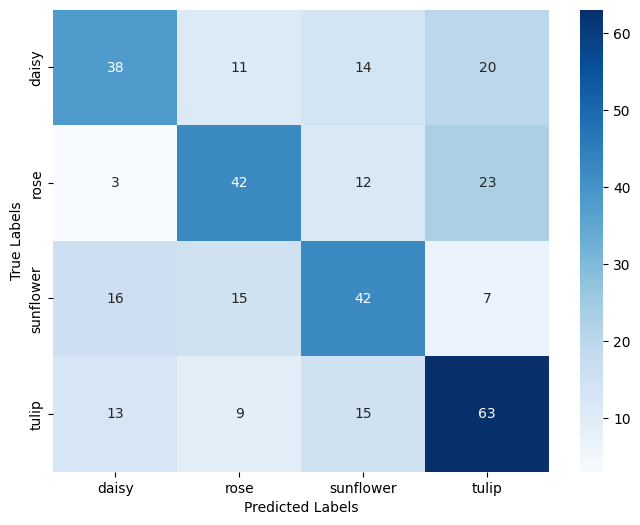

In [ ]:
label_mapping = {0: 'daisy', 1: 'rose', 2: 'sunflower', 3: 'tulip'}
classes = [label_mapping[i] for i in range(len(label_mapping))]

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

LOAD DATA VÀ TRÍCH XUẤT HOG + COLOR HISTOGRAM

In [ ]:
def load_data(data_dir):
    features, labels = [], []
    for label in os.listdir(data_dir):
        label_path = os.path.join(data_dir, label)
        for img in os.listdir(label_path):
          img_path = os.path.join(label_path, img)
          if img.endswith(('.jpg', '.png', '.jpeg')):
            image = cv2.imread(img_path)
            image = cv2.resize(image, (224,224))

            color_hist = extract_histogram(image)
            hog = extract_hog(image)

            feature = np.concatenate([color_hist, hog])

            features.append(feature)
            labels.append(label)

    return np.array(features), np.array(labels)

In [ ]:
X_train, y_train = load_data(train_dir)
X_test, y_test = load_data(test_dir)

In [ ]:
print(X_train.shape)
print(y_test.shape)
print(X_train.shape)
print(y_test.shape)

(2862, 26936)
(343,)
(2862, 26936)
(343,)


In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
y_test = label_encoder.transform(y_test)

RANDOM FOREST DÙNG HOG + COLOR HISTOGRAM


In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_split=10, random_state=42)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy: ", accuracy_score(y_test, y_pred_rf))

print('\n',classification_report(y_test, y_pred_rf))

Random Forest Accuracy:  0.6822157434402333

               precision    recall  f1-score   support

           0       0.69      0.70      0.69        83
           1       0.63      0.59      0.61        80
           2       0.73      0.78      0.75        80
           3       0.68      0.67      0.67       100

    accuracy                           0.68       343
   macro avg       0.68      0.68      0.68       343
weighted avg       0.68      0.68      0.68       343



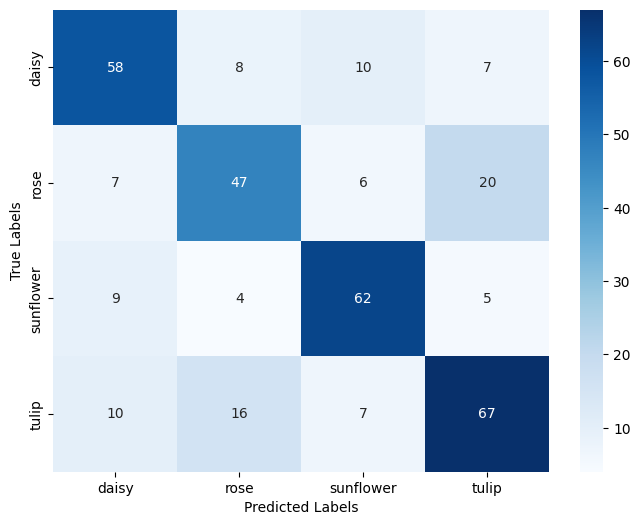

In [ ]:
label_mapping = {0: 'daisy', 1: 'rose', 2: 'sunflower', 3: 'tulip'}
classes = [label_mapping[i] for i in range(len(label_mapping))]

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

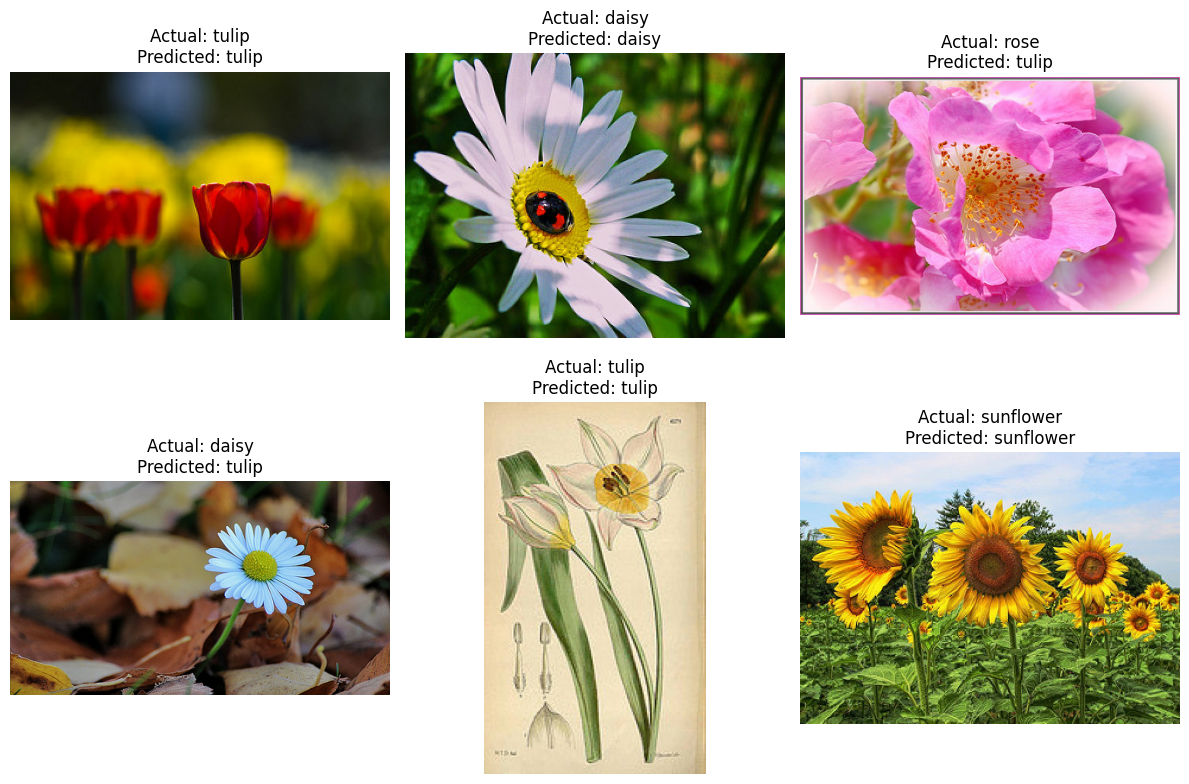

In [ ]:
# dự đoán trên tập test
import random

random_indices = np.random.choice(len(X_test), 6, replace=False)

sample_images = X_test[random_indices]
sample_labels = y_test[random_indices]

sample_preds = rf_model.predict(sample_images)

plt.figure(figsize=(12, 8))

for i, idx in enumerate(random_indices):
    class_name = label_encoder.inverse_transform([y_test[idx]])[0]
    class_path = os.path.join(test_dir, class_name)

    img_name = random.choice(os.listdir(class_path))
    img_path = os.path.join(class_path, img_name)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i+1)
    plt.imshow(img)
    plt.title(f"Actual: {class_name}\nPredicted: {label_encoder.inverse_transform([sample_preds[i]])[0]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


Grid Search

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='accuracy', verbose=2)
grid_rf.fit(X_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best Score:", grid_rf.best_score_)

best_rf_model = grid_rf.best_estimator_
print("Test Accuracy:", best_rf_model.score(X_test, y_test))



Fitting 5 folds for each of 27 candidates, totalling 135 fits
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=  41.6s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=  44.2s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=  40.5s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=  40.4s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=  40.8s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time= 1.3min
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time= 1.4min
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time= 1.3min
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time= 1.4min
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time= 1.3min
[CV] END max_depth=None, min_samples_split=2, n_estimators=300; total time= 2.0min
[CV] END max_depth=None, 

CNN - Convolutional Neural Networks

In [ ]:
classes = ['daisy', 'rose', 'sunflower', 'tulip']

In [ ]:
def load_and_preprocess_images(data_dir, classes, image_size=(224, 224)):

    images = []
    labels = []

    for class_name in classes:
        class_path = os.path.join(data_dir, class_name)
        for file_name in os.listdir(class_path):
            img_path = os.path.join(class_path, file_name)
            img = cv2.imread(img_path)
            if img is not None:
                img_resized = cv2.resize(img, image_size)
                img_resized = img_resized.astype('float32') / 255.0

                images.append(img_resized)
                labels.append(class_name)

    images = np.array(images)
    labels = np.array(labels)

    return images, labels

In [ ]:
X_train_cnn, y_train_cnn = load_and_preprocess_images(train_dir, classes, image_size=(224, 224))
X_test_cnn, y_test_cnn = load_and_preprocess_images(test_dir, classes, image_size=(224, 224))


In [ ]:
print("X_train shape:", X_train_cnn.shape)
print("y_train shape:", y_train_cnn.shape)
print("X_test shape:", X_test_cnn.shape)
print("y_test shape:", y_test_cnn.shape)

X_train shape: (2862, 224, 224, 3)
y_train shape: (2862,)
X_test shape: (343, 224, 224, 3)
y_test shape: (343,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train_cnn, X_val_cnn, y_train_cnn, y_val_cnn = train_test_split(X_train_cnn,
                                                                  y_train_cnn,
                                                                  test_size=0.125,
                                                                  random_state=42)

In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_train_cnn = label_encoder.fit_transform(y_train_cnn)
y_test_cnn = label_encoder.transform(y_test_cnn)
y_val_cnn = label_encoder.transform(y_val_cnn)

In [ ]:
print("y_train_cnn shape:", y_train_cnn.shape)
print("y_test_cnn shape:", y_test_cnn.shape)
print("y_val_cnn shape:", y_val_cnn.shape)

y_train_cnn shape: (2504,)
y_test_cnn shape: (343,)
y_val_cnn shape: (358,)


In [ ]:
from keras.utils import to_categorical
y_train_cnn = to_categorical(y_train_cnn, 4)
y_test_cnn = to_categorical(y_test_cnn, 4)
y_val_cnn = to_categorical(y_val_cnn, 4)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

model = Sequential()

model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Conv2D(256, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dense(256, activation='relu',
                kernel_regularizer=l2(0.01)))
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu',
                kernel_regularizer=l2(0.01)))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))

model.compile(optimizer=Adam(),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train_cnn, y_train_cnn,
                    validation_data = (X_val_cnn,y_val_cnn),
                    epochs = 30)


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 337s 4s/step - accuracy: 0.3735 - loss: 4.0149 - val_accuracy: 0.5363 - val_loss: 1.6374
Epoch 2/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 328s 4s/step - accuracy: 0.5617 - loss: 1.5418 - val_accuracy: 0.5196 - val_loss: 1.3860
Epoch 3/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 334s 4s/step - accuracy: 0.5901 - loss: 1.3156 - val_accuracy: 0.6145 - val_loss: 1.2312
Epoch 4/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 377s 4s/step - accuracy: 0.6264 - loss: 1.1633 - val_accuracy: 0.6341 - val_loss: 1.1511
Epoch 5/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 379s 4s/step - accuracy: 0.6578 - loss: 1.0940 - val_accuracy: 0.6872 - val_loss: 1.0541
Epoch 6/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 390s 4s/step - accuracy: 0.6763 - loss: 1.0447 - val_accuracy: 0.6955 - val_loss: 0.9777
Epoch 7/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 377s 4s/step - accuracy: 0.6938 - loss: 0.9679 - val_accuracy: 0.7039 - val_loss: 0.9831
Epoch 8/30
79/79 ━━━━━━━━━━━━━━━━━━━━ 379s 4s/step - accuracy: 0.7074 - loss: 0.9141 - val_accuracy: 0.7067 - v

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 24, 24, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 12, 12, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 36864)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │       9,437,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 29,577,806 (112.83 MB)

 Trainable params: 9,859,268 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 19,718,538 (75.22 MB)

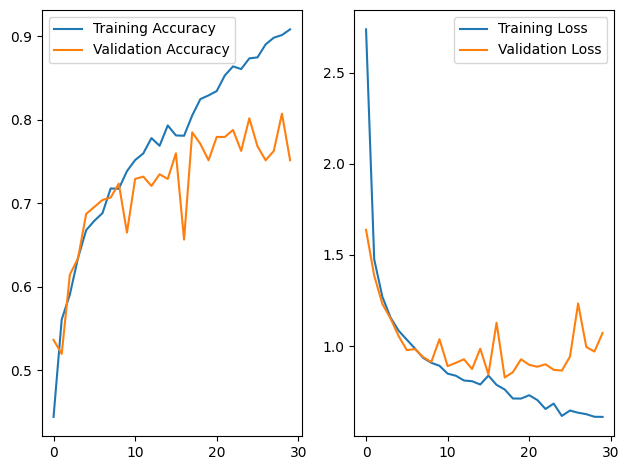

In [ ]:

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(X_test_cnn, y_test_cnn)


11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.7892 - loss: 1.0261


CNN accuracy: 0.7667638659477234
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step
              precision    recall  f1-score   support

       daisy       0.69      0.84      0.76        83
        rose       0.75      0.66      0.70        80
   sunflower       0.98      0.78      0.87        80
       tulip       0.72      0.78      0.75       100

    accuracy                           0.77       343
   macro avg       0.79      0.77      0.77       343
weighted avg       0.78      0.77      0.77       343



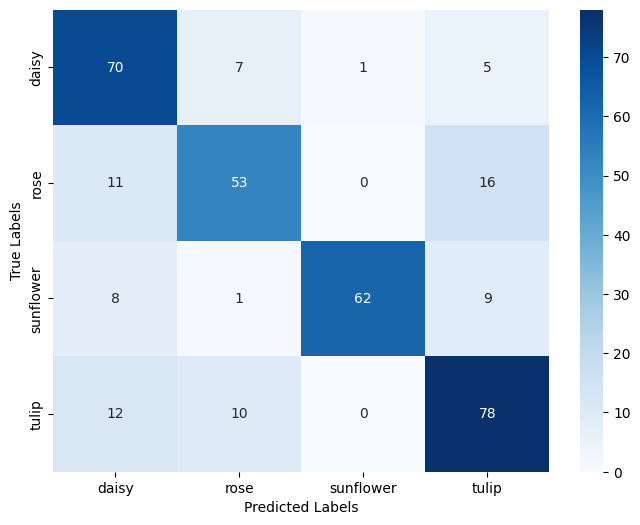

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

print('CNN accuracy:', test_acc)

y_pred_cnn = model.predict(X_test_cnn)
y_pred_cnn_idx = np.argmax(y_pred_cnn, axis=1)
y_test_cnn_idx = np.argmax(y_test_cnn, axis=1)

print(classification_report(y_test_cnn_idx, y_pred_cnn_idx, target_names=classes))

cm = confusion_matrix(y_test_cnn_idx, y_pred_cnn_idx)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)

plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step


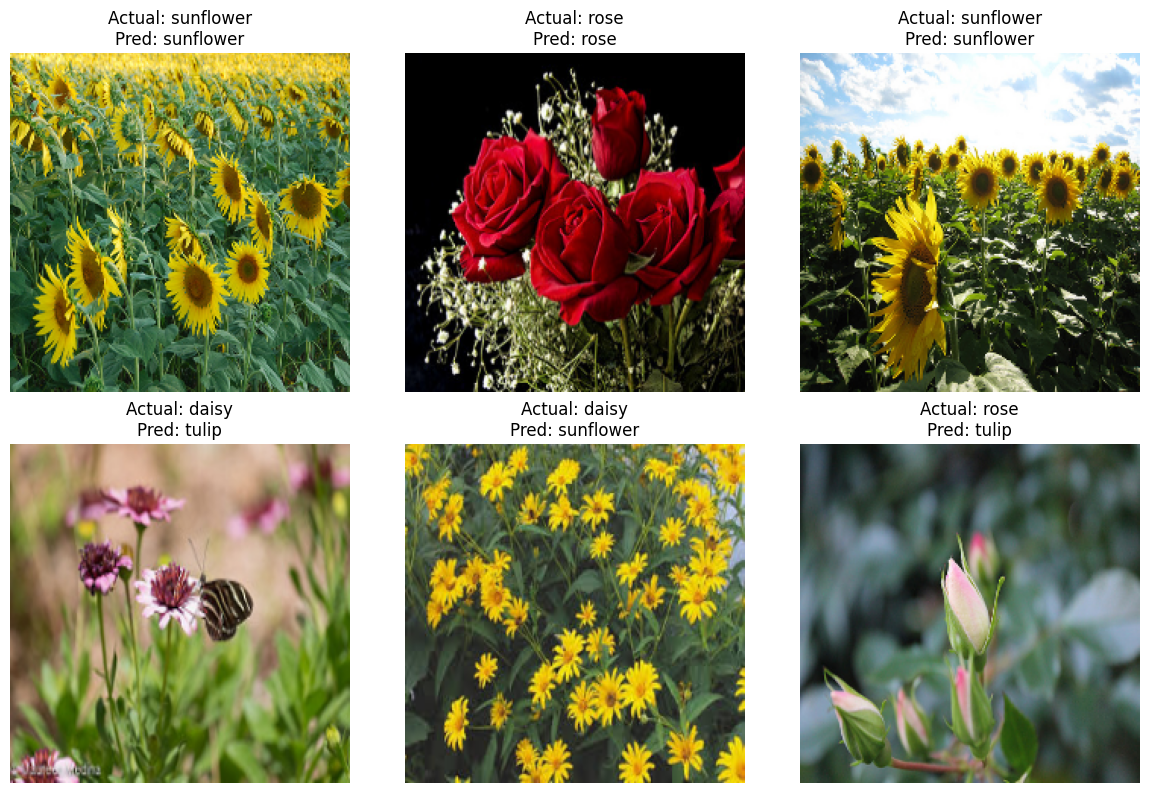

In [ ]:
# Dự đoán ảnh trên test
random_indices = np.random.choice(len(X_test_cnn), 6, replace=False)

random_images = X_test_cnn[random_indices]
random_labels = y_test_cnn[random_indices]

predictions = model.predict(random_images)

predicted_classes = np.argmax(predictions, axis=1)

actual_classes = np.argmax(random_labels, axis=1)

plt.figure(figsize=(12, 8))

for i in range(6):
    img_rgb = cv2.cvtColor((random_images[i] * 255).astype(np.uint8), cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i+1)
    plt.imshow(img_rgb)
    plt.title(f"Actual: {classes[actual_classes[i]]}\nPred: {classes[predicted_classes[i]]}")
    plt.axis('off')

plt.tight_layout()
plt.show()
